# Basic PV tests

Does our chirality statistic transform correctly, detect known chirality, and give zero for symmetric ensembles?

In [1]:
from pathlib import Path
import contextlib
import csv
import html
import io
import itertools
import json
import sys
import numpy as np
from IPython.display import display, Markdown, HTML
PROJECT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                if (p/"src/parity_study").is_dir() and (p/"results").is_dir()),
               Path('/home/users/h/hes/projects/2026_DT_Parity'))
sys.path.insert(0, str(PROJECT/"src"))
from parity_study.paths import OUTPUT_ROOT
RESULTS = OUTPUT_ROOT
OUT = RESULTS/'basic'
(OUT/"figures").mkdir(parents=True, exist_ok=True)
from parity_study.summarize import summarize
from parity_study.storage import atomic_json
from parity_study.catalogue import TEMPLATE, chi_hat_ref
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi":110, "axes.grid":True, "grid.alpha":0.2, "font.size":11})
summaries = {}
for name in ['20261121_baseline']:
    with contextlib.redirect_stdout(io.StringIO()):
        summaries[name] = summarize(RESULTS/name)
    s = summaries[name]
    display(Markdown(f"Saved ensemble **{name}**: {s['completed_records']:,} / "
                     f"{s['expected_records']:,} measurements; "
                     f"**{'complete' if s['complete'] else 'partial — conclusions provisional'}**."))

def save_figure(fig, name):
    for suffix in ("png", "pdf"):
        fig.savefig(OUT/"figures"/f"{name}.{suffix}", dpi=170, bbox_inches="tight")
    plt.show()

def save_table(rows, name):
    if rows:
        with (OUT/f"{name}.csv").open("w", newline="") as stream:
            writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
            writer.writeheader()
            writer.writerows(rows)

def family_p(rows):
    p = [r["p_two_sided"] for r in rows if r.get("p_two_sided") is not None]
    return min(1., len(p)*min(p)) if p else None


def show_table(rows, columns):
    """Display a compact table; columns are (dictionary key, displayed heading)."""
    if not rows:
        display(Markdown("No measurements available for this section."))
        return
    def fmt(value):
        if value is None:
            return "—"
        if isinstance(value, (float, np.floating)):
            return f"{value:.5g}"
        return str(value)
    heading = "".join(f"<th>{html.escape(title)}</th>" for _, title in columns)
    body = "".join("<tr>" + "".join(
        f"<td>{html.escape(fmt(row.get(key)))}</td>" for key, _ in columns) + "</tr>"
        for row in rows)
    display(HTML("<div style='overflow-x:auto'><table><thead><tr>" + heading +
                 "</tr></thead><tbody>" + body + "</tbody></table></div>"))

Saved ensemble **20261121_baseline**: 1,880 / 1,880 measurements; **complete**.

In [2]:
summary = summaries["20261121_baseline"]
RUN = RESULTS/"20261121_baseline"
validation = json.loads((RUN/"validation/report.json").read_text())
positive = [r for r in summary["ensemble_statistics"]
            if r["case"].startswith("positive_") and r["statistic"]=="chi_hat"]
null = [r for r in summary["ensemble_statistics"] if r["case"].startswith("null_")]
geometry_ok = all(v["passed"] for v in validation["T1"].values())
right = next(r for r in positive if r["case"]=="positive_f1")
left = next(r for r in positive if r["case"]=="positive_f0")
controls_ok = right["ci95_low"]>0 and left["ci95_high"]<0
p_null = family_p(null)
display(Markdown(
    f"**Geometry:** {'passes' if geometry_ok else 'check failures'}. "
    f"**Known chirality:** {'recovered' if controls_ok else 'check controls'}. "
    f"**Nulls:** {'no detected bias' if p_null>=.05 else 'inspect deviations'} "
    f"(adjusted p={p_null:.3f})."))

**Geometry:** passes. **Known chirality:** recovered. **Nulls:** no detected bias (adjusted p=0.731).

## 1. What is parity violation?

A parity-odd statistic changes sign under reflection:
$$
S(\mathcal P C)=-S(C).
$$
A parity-symmetric ensemble has $\mathbb E[S]=0$. A nonzero value in one catalogue can arise from sampling noise.

## 2. How do we measure chirality?

Order the four vertices by $s_i=\sum_{j\ne i}|\mathbf r_i-\mathbf r_j|^2$. From the first ordered vertex, form the three edge vectors $\mathbf v_1,\mathbf v_2,\mathbf v_3$:
$$
\chi=\det(\mathbf v_1,\mathbf v_2,\mathbf v_3),\qquad
\widehat\chi=\frac{\chi}{|\mathbf v_1||\mathbf v_2||\mathbf v_3|}\in[-1,1].
$$
Average over the catalogue's tetrahedra. This ordering makes the sign independent of input vertex labels; tied scores receive zero weight.

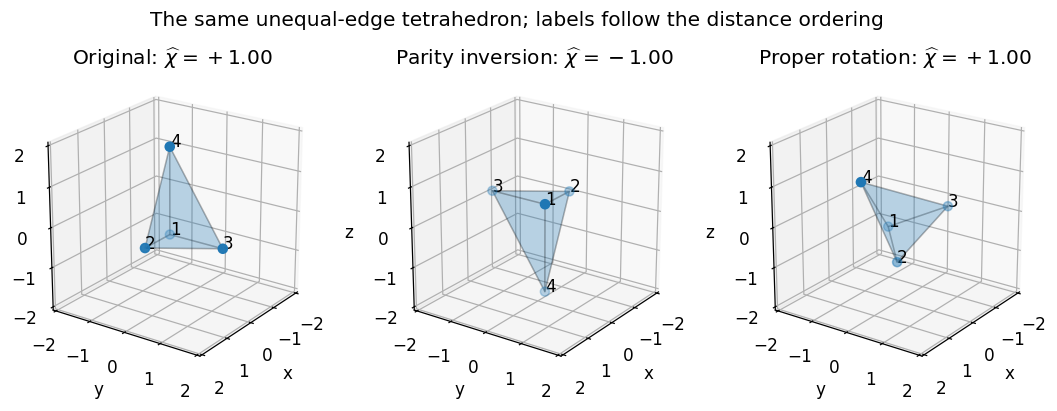

Transformation,Normalized chirality
Original,1
Parity inversion,-1
Proper rotation,1


**Answer:** reflection flips the sign; rotation preserves it. All 24 input vertex permutations agree, with maximum difference 0.

In [3]:
from scipy.spatial.transform import Rotation
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
shape = TEMPLATE-TEMPLATE.mean(axis=0)
rot = Rotation.from_euler("xyz",[25,35,50],degrees=True).as_matrix()
shapes = [shape, -shape, shape@rot.T]
labels = ["Original", "Parity inversion", "Proper rotation"]
fig = plt.figure(figsize=(12,4))
values = []
for index, (points,label) in enumerate(zip(shapes,labels),1):
    score = ((points[:,None]-points[None])**2).sum(axis=-1).sum(axis=1)
    ordered = points[np.argsort(score)]
    value = float(chi_hat_ref(points))
    values.append(dict(transformation=label, chi_hat=value))
    ax = fig.add_subplot(1,3,index,projection="3d")
    faces = [ordered[list(face)] for face in itertools.combinations(range(4),3)]
    ax.add_collection3d(Poly3DCollection(faces,alpha=.16,facecolor="tab:blue",edgecolor="k"))
    ax.scatter(*ordered.T,s=35,color="tab:blue")
    for j,point in enumerate(ordered,1):
        ax.text(*point,str(j),fontsize=11)
    ax.set(xlim=(-2,2),ylim=(-2,2),zlim=(-2,2),xlabel="x",ylabel="y",zlabel="z",
           title=label+rf": $\widehat\chi={value:+.2f}$")
    ax.set_box_aspect((1,1,1))
    ax.view_init(elev=22,azim=35)
fig.suptitle("The same unequal-edge tetrahedron; labels follow the distance ordering")
save_figure(fig,"tetrahedron_handedness")
permuted = np.array([chi_hat_ref(shape[list(p)]) for p in itertools.permutations(range(4))])
relabel_error = float(np.max(abs(permuted-chi_hat_ref(shape))))
show_table(values,[("transformation","Transformation"),("chi_hat","Normalized chirality")])
display(Markdown(f"**Answer:** reflection flips the sign; rotation preserves it. "
                 f"All 24 input vertex permutations agree, with maximum difference {relabel_error:.3g}."))
save_table(values,"tetrahedron_example")

## 3. Does the full pipeline transform correctly?

Reference: 10,000 points, $L=1000$.
**Expected:** reflections flip the sign; rotations and translations preserve it. Cell counts and total volume stay unchanged.

In [4]:
signs = {"reference":1,"inversion":-1,"swap":-1,"rotation90":1,"translation":1}
reference = validation["T1"]["reference"]["sum_chi_hat"]
geometry = [dict(transformation=name, expected_sum=signs[name]*reference, **v)
            for name,v in validation["T1"].items()]
show_table(geometry,[("transformation","Transformation"),("expected_sum","Expected sum χ̂"),
                    ("sum_chi_hat","Measured sum χ̂"),("absolute_error","Absolute error"),
                    ("n_tetrahedra","Tetrahedra"),("volume_fraction","Volume / box"),
                    ("passed","Passed")])
geometry_pass = all(r["passed"] for r in geometry)
max_error = max(r["absolute_error"] for r in geometry)
display(Markdown(f"**Answer:** {'all transformations pass' if geometry_pass else 'inspect failed checks'}. "
                 f"The largest chirality-sum error is {max_error:.3g}. "
                 ""))
save_table(geometry,"geometry_checks")

Transformation,Expected sum χ̂,Measured sum χ̂,Absolute error,Tetrahedra,Volume / box,Passed
reference,-6.8053,-6.8053,0,67576,1,True
inversion,6.8053,6.8053,2.0073e-13,67576,1,True
swap,6.8053,6.8053,2.8422e-14,67576,1,True
rotation90,-6.8053,-6.8053,5.258e-13,67576,1,True
translation,-6.8053,-6.8053,5.2225e-13,67576,1,True


**Answer:** all transformations pass. The largest chirality-sum error is 5.26e-13. 

## 4. Can we recover known chirality?

2,500 randomly oriented molecules per catalogue; 20 seeds per right-handed fraction $f_R$.
**Expected:** molecule mean $\widehat\chi\simeq2f_R-1$; the full-catalogue signal is diluted. Error bars: 1 SEM across seeds.

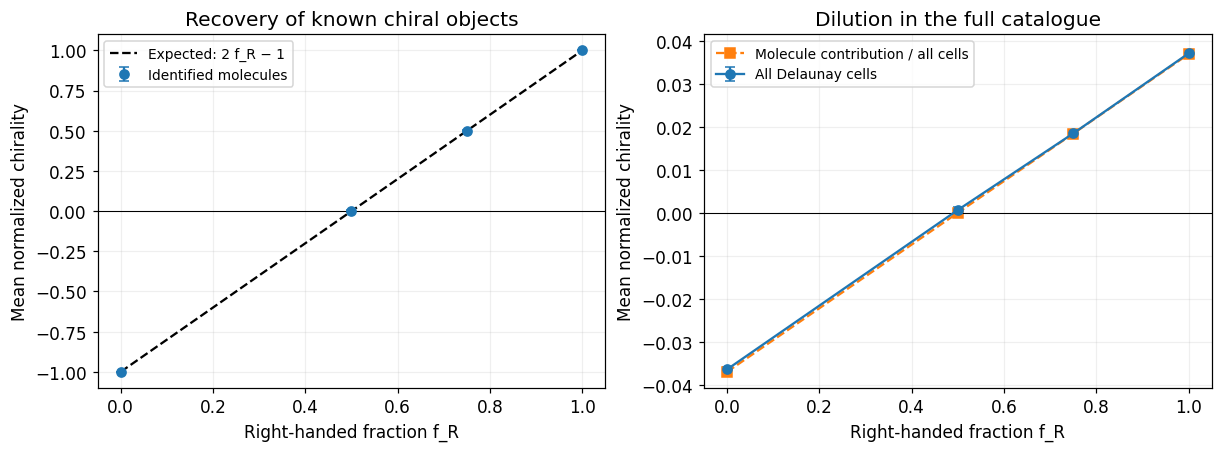

Case,Catalogues,Mean χ̂,SEM,95% interval low,95% interval high
positive_f0,20,-0.036366,0.00058242,-0.037585,-0.035147
positive_f0.5,20,0.00070046,0.00067628,-0.00071501,0.0021159
positive_f0.75,20,0.018507,0.00070777,0.017025,0.019988
positive_f1,20,0.037122,0.00066188,0.035736,0.038507


**Answer:** both injected signs are recovered. The balanced mixture is +1.04 SEM from zero. 

In [5]:
fractions = [float(r["case"].split("_f")[1]) for r in positive]
molecules = summary["molecular_controls"]
def molecule_rows(quantity):
    return sorted([r for r in molecules if r["quantity"]==quantity],
                  key=lambda r:float(r["case"].split("_f")[1]))
fig,axes = plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
identified = molecule_rows("measured_mean")
axes[0].plot([0,1],[-1,1],"k--",label="Expected: 2 f_R − 1")
axes[0].errorbar(fractions,[r["mean"] for r in identified],
                 yerr=[r["sem"] for r in identified],fmt="o",capsize=3,label="Identified molecules")
axes[1].errorbar(fractions,[r["mean"] for r in positive],yerr=[r["sem"] for r in positive],
                 fmt="o-",capsize=3,label="All Delaunay cells")
contribution = molecule_rows("molecule_contribution_to_all")
axes[1].plot(fractions,[r["mean"] for r in contribution],"s--",label="Molecule contribution / all cells")
for ax in axes:
    ax.axhline(0,color="k",lw=.7)
    ax.set(xlabel="Right-handed fraction f_R",ylabel="Mean normalized chirality")
    ax.legend(fontsize=9)
axes[0].set_title("Recovery of known chiral objects")
axes[1].set_title("Dilution in the full catalogue")
save_figure(fig,"positive_controls")
show_table(positive,[("case","Case"),("n","Catalogues"),("mean","Mean χ̂"),("sem","SEM"),
                     ("ci95_low","95% interval low"),("ci95_high","95% interval high")])
left = next(r for r in positive if r["case"]=="positive_f0")
right = next(r for r in positive if r["case"]=="positive_f1")
balanced = next(r for r in positive if r["case"]=="positive_f0.5")
recovered = left["ci95_high"]<0 and right["ci95_low"]>0
display(Markdown(f"**Answer:** {'both injected signs are recovered' if recovered else 'the controls need inspection'}. "
                 f"The balanced mixture is {balanced['t']:+.2f} SEM from zero. "
                 ""))
save_table(positive,"positive_controls")
save_table(molecules,"molecule_diagnostics")

## 5. Are symmetric ensembles consistent with zero?

200 seeds per null, using the original amplitude convention:

| Null | Parameters |
| --- | --- |
| Poisson | Undisplaced, L=1000 |
| Equal helicity | ε=0, A=0.002, L=1000 |
| Strong displacement | ε=0, A=1, L=1 |

Plot: mean $\widehat\chi$ and 95% intervals across seeds. The family p-value accounts for all nine null comparisons.

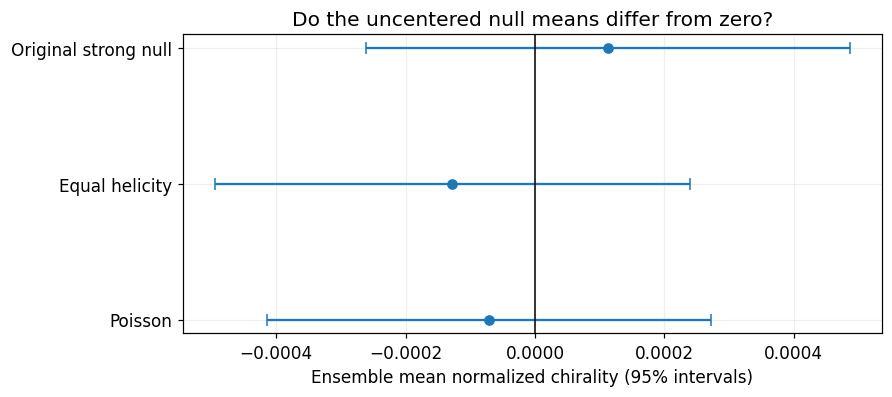

Null,Statistic,Catalogues,Mean,SEM,Mean / SEM,Uncorrected p
null_poisson,chi,200,5.0556,29.357,0.17221,0.86345
null_poisson,chi_hat,200,-7.109e-05,0.00017406,-0.40841,0.68341
null_poisson,sgn,200,-1.8615e-05,0.00025128,-0.074079,0.94102
null_symmetric,chi,200,-24.383,31.915,-0.76401,0.44577
null_symmetric,chi_hat,200,-0.00012753,0.00018637,-0.68426,0.49461
null_symmetric,sgn,200,-0.00020313,0.00027171,-0.7476,0.45558
null_notebook_L1_A1,chi,200,5.3683e-08,3.0632e-08,1.7525,0.081222
null_notebook_L1_A1,chi_hat,200,0.00011302,0.00018961,0.59609,0.55179
null_notebook_L1_A1,sgn,200,0.00023756,0.00027913,0.85106,0.39576


**Answer:** no null bias is detected. The conservative family p-value is 0.731. 

In [6]:
selected = [r for r in null if r["statistic"]=="chi_hat"]
case_labels = {"null_poisson":"Poisson","null_symmetric":"Equal helicity",
               "null_notebook_L1_A1":"Original strong null"}
fig,ax = plt.subplots(figsize=(8,3.5),constrained_layout=True)
means = np.array([r["mean"] for r in selected])
low = np.array([r["ci95_low"] for r in selected])
high = np.array([r["ci95_high"] for r in selected])
ax.errorbar(means,np.arange(len(selected)),xerr=[means-low,high-means],fmt="o",capsize=4)
ax.axvline(0,color="k",lw=1)
ax.set(yticks=np.arange(len(selected)),yticklabels=[case_labels[r["case"]] for r in selected],
       xlabel="Ensemble mean normalized chirality (95% intervals)",
       title="Do the uncentered null means differ from zero?")
save_figure(fig,"null_means")
show_table(null,[("case","Null"),("statistic","Statistic"),("n","Catalogues"),
                 ("mean","Mean"),("sem","SEM"),("t","Mean / SEM"),("p_two_sided","Uncorrected p")])
p_null = family_p(null)
display(Markdown(f"**Answer:** {'no null bias is detected' if p_null>=.05 else 'inspect the null deviations'}. "
                 f"The conservative family p-value is {p_null:.3g}. "
                 ""))
save_table(null,"null_controls")

In [7]:
atomic_json(OUT/"conclusions.json",dict(geometry_pass=geometry_pass,
    geometry_max_error=max_error,vertex_relabelling_max_error=relabel_error,
    positive_controls_recovered=recovered,null_family_p=p_null,
    source_run=RUN.name,source_complete=summary["complete"]))

[Figures](saved/basic/figures/) · [Tables](saved/basic/) · [Displacement model](intro_PVdisp.ipynb)